In [1]:
from pyscf import gto, scf
import numpy as np
from oracles import *
import scipy as sp
from python_impls.pure_scf import *
from python_impls.cg_scf import *
from python_impls.cbcd_scf import *
from code_in_c.fast_scf import *   # ← add this line

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pgf import FigureCanvasPgf
from cycler import cycler
import awkward as ak
from pprint import pprint
import json
from datetime import datetime
import re
import os

# matplotlib 3.11's usetex PDF backend silently drops minus signs (log-axis
# exponents 10^{-n}, "$-$", etc.) — they show in PNG but not PDF. Route all
# .pdf saves through the pgf backend (typesets via pdflatex) so minuses embed
# correctly. PNG saves still use the default (Agg + usetex).
matplotlib.backend_bases.register_backend("pdf", FigureCanvasPgf)

# --- Match the PRB (REVTeX4-2 reprint, aps/prb) manuscript -----------------
# Body font is 10 pt; every figure text element is set to 10 pt so it renders
# 1:1 with the manuscript. Points only match if the figure's physical width
# equals the placement width, so figures default to the PRB single-column
# width (\columnwidth = 246 pt = 3.404 in). Full-width (figure*) plots override
# figsize to \textwidth (510 pt = 7.057 in) below. Set "text.usetex" to False
# to fall back to mathtext if a LaTeX install is unavailable.
PRB_COLUMN_WIDTH = 246.0 / 72.27  # inches, PRB \columnwidth (3.404 in)
PRB_TEXT_WIDTH = 510.0 / 72.27  # inches, PRB \textwidth  (7.057 in)

# Okabe-Ito colorblind-safe palette, in series order (Diagonalization, CG, CBCD c=0/1/2/N).
# Setting it as the color cycle colors the grouped bars and auto-colored lines.
OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7"]
SERIES_COLOR = dict(
    zip(["Diagonalization", "CG", "CBCD c=0", "CBCD c=1", "CBCD c=2", "CBCD c=N"], OKABE_ITO)
)

hatches = [r"//", r"\\", "", "", "", ""]

plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "figure.titlesize": 10,
        "figure.figsize": (PRB_COLUMN_WIDTH, PRB_COLUMN_WIDTH * 0.75),
        "axes.prop_cycle": cycler(color=OKABE_ITO),
        "axes.unicode_minus": False,
        # pgf backend (used for .pdf saves, see register_backend above).
        "pgf.texsystem": "pdflatex",
        "pgf.rcfonts": False,
        # Keep the saved figure exactly figsize wide (no tight-bbox crop) so a
        # width=\linewidth include scales by 1 and 10 pt stays 10 pt.
        "figure.constrained_layout.use": True,
    }
)

In [2]:
# molecules = [
#     "Al2H6", "AlH3", "BF3", "BH3",
#     "C2H2", "C2H4", "C2H6", "C3H4", "C3H6", "C3H8", "C4H10", "C4H6",
#     "C4H8", "C5H10", "C5H12", "C5H8", "C6H10", "C6H12", "C6H14", "C6H6",
#     "CCl4", "CH3COOH", "CH3Cl", "CH3OH", "CH4", "H2",
#     "H2O", "H2S", "H2SO3", "H2SO4", "H2Se", "H3PO4", "HBr", "HCl",
#     "HF", "KF", "LiF", "MgF2", "N2", "N2O5", "NH3", "NaBr", "NaCl",
#     "NaF", "PF5", "PH3", "SO2", "SeO2", "SiH4", "SiO2",
# ]

# molecules = ["CCl4", "PF5", "N2O5", "SeO2", "H3PO4", "H2SO4", "C6H14", "C6H12", "NaBr", "C6H10"]

# Previous 7-molecule set:
molecules = ["H2", "H2O", "NH3", "CH4", "F2", "HCl", "SO2"]


# Closed-shell, aug-cc-pVTZ-supported, all <= ~150 basis fns (ERI memory cap).
# Spans H2(46) -> SO2(142) with ionic (LiF), triple-bond (N2), and 2nd-row variety.
# molecules = ["H2", "HF", "HCl", "N2", "H2O", "F2", "LiF", "H2S", "Cl2",
#              "NH3", "PH3", "C2H2", "CH4", "SiH4", "SO2"]
dp_list = [0.4 for i in range(len(molecules))]
timings = {}
adjusted_timings = {}


# check some conv issues

In [3]:
for molecule, dp in zip(molecules, dp_list):
    print(f"Molecule: {molecule}")
    with open(f"../ref_data/{molecule}.txt") as f:
        mol_atom_str = "".join(f.readlines()[1:])  # skip header row

    mol = gto.Mole()
    # mol.output = 'out_h2o'
    mol.atom = mol_atom_str
    # mol.basis = '6-31g*'
    mol.basis = "aug-cc-pVTZ"
    mol.build()
    ne = mol.nelectron
    integ = build_integrals(mol)
    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    mf_guess = scf.RHF(mol)
    mf_guess.max_cycle = 0
    print(f"Initial non-nuclear_E : {mf_guess.kernel() - mol.get_enuc()}")

    S = mf_guess.get_ovlp()
    X = np.real(sp.linalg.fractional_matrix_power(S, 0.5))
    C0_orth = X @ mf_guess.mo_coeff[:, : ne // 2]

    mf = scf.RHF(mol)
    e_pyscf = mf.kernel() - mol.get_enuc()
    print(f"non-nuclear_E : {e_pyscf}")

    # print(np.linalg.norm(C0_orth.T @ C0_orth - np.eye(C0_orth.shape[1])))  # ≈ 0

    runs = 11
    timing_cg = []
    timing_cbcd1 = []
    timing_cbcd0 = []
    # timing_cbcd2 = []
    timing_cbcd_ncols = []
    timing_scf = []

    e_times_cg = []
    e_times_cbcd1 = []
    # e_times_cbcd2 = []
    e_times_cbcd_ncols = []
    e_times_cbcd0 = []
    e_times_scf = []

    c_value = 0
    print(f"CBCD, c = {c_value}")

    for i in range(runs):
        etar = 0
        C_init = np.copy(C0_orth)
        while etar - e_pyscf > 1e-4:
            mat, etar, (tcbcd, et) = cbcd_scf(
                f,
                grad,
                C_init,
                c_value,
                timing=True,
                eps=1e-6,
                ITER_MAX=10000,
                expressive=False,
                damp_param=dp,
            )
            if etar - e_pyscf > 1e-4:
                print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
        timing_cbcd0.append(tcbcd)
        e_times_cbcd0.append(tcbcd - et)

    print(f"Variational Error? {(etar - e_pyscf)}")
    print(f"Median Time over {runs} runs: {np.median(timing_cbcd0)}")
    print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_cbcd0)}")

    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    print("Diagonalization")
    for i in range(runs):
        C_init = np.copy(C0_orth)
        mat, etar, (tscf, et) = pure_scf(
            f,
            C_init,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
        )
        timing_scf.append(tscf)
        e_times_scf.append(tscf - et)

    print(f"Variational Error? {(etar - e_pyscf)}")
    print(f"Median Time over {runs} runs: {np.median(timing_scf)}")
    print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_scf)}")

    if etar - e_pyscf > 1e-4:
        print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
        break

    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    print("CG")
    for i in range(runs):
        C_init = np.copy(C0_orth)
        mat, etar, (tcg, et) = cg_scf(
            f,
            grad,
            C_init,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
        )
        timing_cg.append(tcg)
        e_times_cg.append(tcg - et)

    print(f"Variational Error? {(etar - e_pyscf)}")
    print(f"Median Time over {runs} runs: {np.median(timing_cg)}")
    print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_cg)}")

    if etar - e_pyscf > 1e-4:
        print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
        break

    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    # c_value = 2
    # print(f"CBCD, c = {c_value}")

    # for i in range(runs):
    #     C_init = np.copy(C0_orth)
    #     mat, etar, (tcbcd, et) = cbcd_scf(
    #         f,
    #         grad,
    #         C_init,
    #         c_value,
    #         timing=True,
    #         eps=1e-6,
    #         ITER_MAX=10000,
    #         expressive=False,
    #         damp_param=dp,
    #         fast_proj=False,
    #     )
    #     timing_cbcd2.append(tcbcd)
    #     e_times_cbcd2.append(tcbcd - et)

    # print(f"Variational Error? {(etar - e_pyscf)}")
    # print(f"Median Time over {runs} runs: {np.median(timing_cbcd2)}")
    # print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_cbcd2)}")

    # if etar - e_pyscf > 1e-4:
    #     print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
    #     break

    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    c_value = 1
    print(f"CBCD, c = {c_value}")

    for i in range(runs):
        C_init = np.copy(C0_orth)
        mat, etar, (tcbcd, et) = cbcd_scf(
            f,
            grad,
            C_init,
            c_value,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
            fast_proj=False,
        )
        timing_cbcd1.append(tcbcd)
        e_times_cbcd1.append(tcbcd - et)

    print(f"Variational Error? {(etar - e_pyscf)}")
    print(f"Median Time over {runs} runs: {np.median(timing_cbcd1)}")
    print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_cbcd1)}")

    if etar - e_pyscf > 1e-4:
        print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
        break

    f = make_rhf_oracle_energy(integ, ne)
    grad = make_rhf_grad_energy(f)

    c_value = mat.shape[1]
    print(f"CBCD, c = {c_value} (columns in C)")

    for i in range(runs):
        C_init = np.copy(C0_orth)
        mat, etar, (tcbcd, et) = cbcd_scf(
            f,
            grad,
            C_init,
            c_value,
            timing=True,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=False,
            damp_param=dp,
            fast_proj=True,
        )
        timing_cbcd_ncols.append(tcbcd)
        e_times_cbcd_ncols.append(tcbcd - et)

    print(f"Variational Error? {(etar - e_pyscf)}")
    print(f"Median Time over {runs} runs: {np.median(timing_cbcd_ncols)}")
    print(f"Non-N^4 Time over {runs} runs: {np.median(e_times_cbcd_ncols)}")

    if etar - e_pyscf > 1e-4:
        print("ERROR: Energy not in agreement with PySCF to chemical accuracy")
        break

    timings[molecule] = (
        np.median(timing_scf),
        np.median(timing_cg),
        np.median(timing_cbcd0),
        np.median(timing_cbcd1),
        # np.median(timing_cbcd2),
        np.median(timing_cbcd_ncols),
    )
    adjusted_timings[molecule] = (
        np.median(e_times_scf),
        np.median(e_times_cg),
        np.median(e_times_cbcd0),
        np.median(e_times_cbcd1),
        # np.median(e_times_cbcd2),
        np.median(e_times_cbcd_ncols),
    )

Molecule: H2
SCF not converged.
SCF energy = -0.817399217275657
Initial non-nuclear_E : -1.5603814547425574
converged SCF energy = -1.13268570630928
non-nuclear_E : -1.8756679437761834
CBCD, c = 0
Variational Error? 4.521449090688634e-07
Median Time over 11 runs: 0.0006411670474335551
Non-N^4 Time over 11 runs: 3.9291917346417904e-05
Diagonalization
Variational Error? 2.7513397937717343e-07
Median Time over 11 runs: 0.0009349159663543105
Non-N^4 Time over 11 runs: 0.0002634151605889201
CG
Variational Error? 2.887504249038386e-07
Median Time over 11 runs: 0.0007222909480333328
Non-N^4 Time over 11 runs: 3.0290917493402958e-05
CBCD, c = 1
Variational Error? 4.521449090688634e-07
Median Time over 11 runs: 0.0006709590088576078
Non-N^4 Time over 11 runs: 3.487500362098217e-05
CBCD, c = 1 (columns in C)
Variational Error? 4.521449090688634e-07
Median Time over 11 runs: 0.0006054580444470048
Non-N^4 Time over 11 runs: 3.633182495832443e-05
Molecule: H2O
SCF not converged.
SCF energy = -75.82

In [4]:
# Order the x-axis by number of electrons (least -> most), tie-broken by number
# of basis functions. Rebuilds a lightweight Mole per molecule (cheap).
def _size(m):
    with open(f"../ref_data/{m}.txt") as fh:
        atom = "".join(fh.readlines()[1:])
    mm = gto.Mole()
    mm.atom = atom
    mm.basis = mol.basis
    mm.build(verbose=0)
    return (mm.nelectron, mm.nao)


order = sorted(molecules, key=_size)

timings_by_method = {}
scf_time = []
cg = []
cbcd_0 = []
cbcd_1 = []
cbcd_2 = []
cbcd_ncols = []
methods = [scf_time, cg, cbcd_0, cbcd_1, 
# cbcd_2, 
cbcd_ncols]
for m in order:
    times = timings[m]
    for i in range(len(times)):
        methods[i].append(times[i])

timings_by_method["Diagonalization"] = scf_time
timings_by_method["CG"] = cg
timings_by_method[r"CBCD, $c = 0$"] = cbcd_0
timings_by_method[r"CBCD, $c = 1$"] = cbcd_1
# timings_by_method[r"CBCD, $c = 2$"] = cbcd_2
timings_by_method[r"CBCD, $c = N_o$"] = cbcd_ncols


adjusted_timings_by_method = {}
e_scf_time = []
e_cg = []
e_cbcd_0 = []
e_cbcd_1 = []
# e_cbcd_2 = []
e_cbcd_ncols = []

e_methods = [e_scf_time, e_cg, e_cbcd_0, e_cbcd_1,
            #   e_cbcd_2, 
              e_cbcd_ncols]
for m in order:
    times = adjusted_timings[m]
    for i in range(len(times)):
        e_methods[i].append(times[i])


adjusted_timings_by_method["Diagonalization"] = e_scf_time
adjusted_timings_by_method["CG"] = e_cg
adjusted_timings_by_method[r"CBCD, $c = 0$"] = e_cbcd_0
adjusted_timings_by_method[r"CBCD, $c = 1$"] = e_cbcd_1
# adjusted_timings_by_method[r"CBCD, $c = 2$"] = e_cbcd_2
adjusted_timings_by_method[r"CBCD, $c = N_o$"] = e_cbcd_ncols


timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
out_dir = f"data/timing/{timestamp}"
os.makedirs(out_dir, exist_ok=True)

info = {
    "timings": timings_by_method,
    "adjusted timings": adjusted_timings_by_method,
    "molecules": order,
    "basis": mol.basis,
}

with open(f"{out_dir}/data.json", "w", encoding="utf-8") as json_file:
    json.dump(info, json_file, indent=4)

print(f"Output directory: {out_dir}")

Output directory: data/timing/2026-11-10_11-51-11


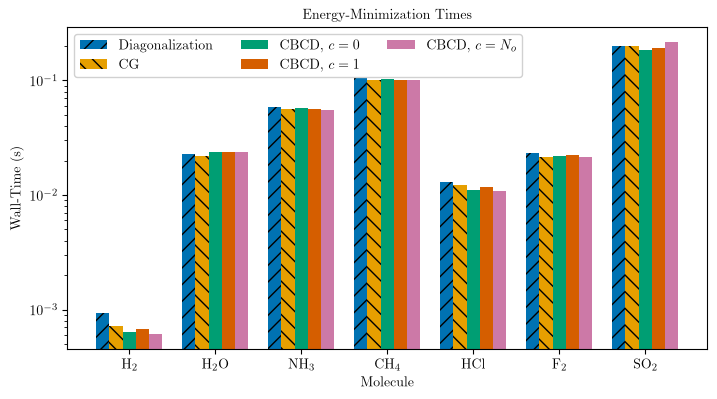

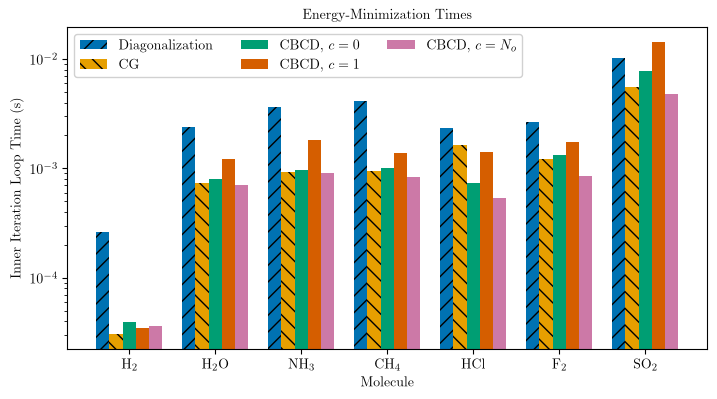

In [5]:
def chem_to_latex(formula):
    return r"$\mathrm{" + re.sub(r"(\d+)", r"_{\1}", formula) + r"}$"


mol_strings = [
    chem_to_latex(m) for m in order
]  # `order` = molecules sorted by #electrons


bar_colors = [SERIES_COLOR[k] for k in ["Diagonalization", "CG", "CBCD c=0", "CBCD c=1", "CBCD c=N"]]


# Full-width (figure*) so the dense 6-series groups have horizontal room; the
# height is set tall enough that the long y-axis label fits without clipping.
fig, ax = plt.subplots(figsize=(PRB_TEXT_WIDTH, PRB_TEXT_WIDTH * 0.55))
ax.grouped_bar(
    # timings_by_method, tick_labels=mol_strings, hatch=hatches, rasterized=True
    timings_by_method, tick_labels=mol_strings, colors=bar_colors, hatch=hatches, rasterized=True
)

ax.set_yscale("log")
ax.set_ylabel(r"Wall-Time (s)")
ax.set_xlabel(r"Molecule")
ax.set_title(r"Energy-Minimization Times")
ax.legend(loc="upper left", ncols=3, framealpha=0.9)
plt.savefig(f"{out_dir}/plot_true_walltime.png", dpi=300)
plt.savefig(f"{out_dir}/plot_true_walltime.pdf")

plt.show()


fig, ax = plt.subplots(figsize=(PRB_TEXT_WIDTH, PRB_TEXT_WIDTH * 0.55))
ax.grouped_bar(
    # adjusted_timings_by_method, tick_labels=mol_strings, hatch=hatches, rasterized=True
    adjusted_timings_by_method, tick_labels=mol_strings, colors=bar_colors, hatch=hatches, rasterized=True
)

ax.set_yscale("log")
ax.set_ylabel(r"Inner Iteration Loop Time (s)")
ax.set_xlabel(r"Molecule")
ax.set_title(r"Energy-Minimization Times")
ax.legend(loc="upper left", ncols=3, framealpha=0.9)

plt.savefig(f"{out_dir}/plot_corrected_walltime.png", dpi=300)
plt.savefig(f"{out_dir}/plot_corrected_walltime.pdf")

plt.show()

In [6]:
from pathlib import Path

# Walk up from the notebook's cwd to the repo root (the dir containing manuscript/),
# so this works regardless of where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ref_data").is_dir())
FIGDIR = ROOT.parent / "manuscript" / "new_figures"

fig.savefig(FIGDIR / "plot_corrected_walltime.pdf", bbox_inches="tight")
fig.savefig(FIGDIR / "plot_corrected_walltime.png", dpi=300, bbox_inches="tight")
print("wrote to", FIGDIR)

wrote to /Users/nilay/Library/CloudStorage/OneDrive-Personnel/Documents/Cornell/ManOpt/Code/Energies/gs_cbcd/manuscript/new_figures


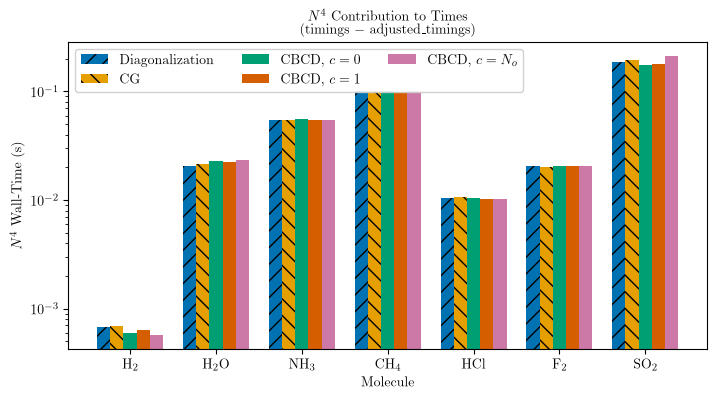

In [7]:
diff_timings_by_method = {
    method: [
        t - a
        for t, a in zip(timings_by_method[method], adjusted_timings_by_method[method])
    ]
    for method in timings_by_method
}

fig, ax = plt.subplots(figsize=(PRB_TEXT_WIDTH, PRB_TEXT_WIDTH * 0.55))
ax.grouped_bar(
    # diff_timings_by_method, tick_labels=mol_strings, hatch=hatches, rasterized=True
    diff_timings_by_method, tick_labels=mol_strings, colors=bar_colors, hatch=hatches, rasterized=True
)
ax.set_ylabel(r"$N^4$ Wall-Time (s)")
ax.set_xlabel(r"Molecule")
ax.set_yscale("log")
ax.set_title(r"$N^4$ Contribution to Times" + "\n" + r"(timings $-$ adjusted\_timings)")
ax.legend(loc="upper left", ncols=3, framealpha=0.9)
plt.savefig(f"{out_dir}/walltime_correction.png", dpi=300)
plt.savefig(f"{out_dir}/walltime_correction.pdf")

plt.show()

In [8]:
# TODO:
# update labels to be in tex
# molecule numbers as subscripts

Some...oddities

for $SO_2$, I notice convergence only for Canonical and CBCD (c = 1)--all others seem to go to the wrong point, possibly a result of convergence to the wrong value at the first Canonical iteration. Interesting.


Fpr $B_2H_6$, CG fails. CBCD (c=1) and Canonical do not.

The damping is sometimes insufficient (0.4 is insufficient for $C_4H_6, C_4H_8, N_2O_5$ for Canonical to converge; for $N_2O_5$ the other two are okay (c=1), and only CG works on $C_4H_6$ (the other two don't work))


But if you wanna see something cool, note that CBCD (c=4!) beats CG on HCl, or c=7 for Al2H6

Canonical doesn't appear to converge for $O_2$ no matter hte damping parameter. CBCD (c=0,1,2) and CG are unaffected. In 6-31-g, only c=1 CBCD works

$F_2$ convergence oissues for $c=0$--in 6-31g only c=1 and CG; still issues with c=0 sometimes (!!!!)


C3H8 is giving me memory issues


this may have had to do with initial guess--atom guesses seem better behaved? 

